In [27]:
# Simulación de un proceso MA(1), esto es, ARMA(0,1)
import numpy as np
from statsmodels.tsa.arima_process import ArmaProcess
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
import warnings
import os
warnings.filterwarnings("ignore")

In [2]:
ar1 = np.array([1, 0])
ma1 = np.array([1, -0.9])

In [3]:
MA_object1 = ArmaProcess(ar1, ma1)
simulated_data = MA_object1.generate_sample(nsample=10000)

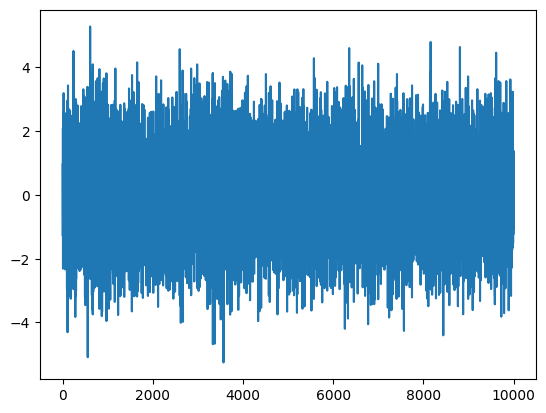

In [4]:
plt.plot(simulated_data)

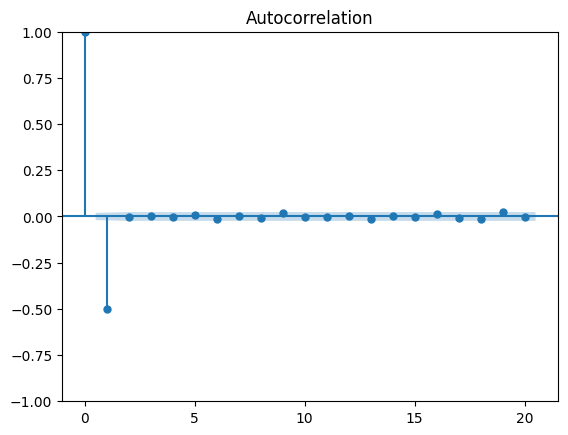

In [5]:
from statsmodels.graphics.tsaplots import plot_acf
plot_acf(simulated_data, lags=20)
plt.show()

In [6]:
# Proceso de estimación de parámetro
from statsmodels.tsa.arima.model import ARIMA
mod = ARIMA(simulated_data, order=(0,0,1))
result = mod.fit()
print(result.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                10000
Model:                 ARIMA(0, 0, 1)   Log Likelihood              -14251.458
Date:                Tue, 20 Oct 2026   AIC                          28508.917
Time:                        11:06:38   BIC                          28530.548
Sample:                             0   HQIC                         28516.239
                              - 10000                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0013      0.001      1.344      0.179      -0.001       0.003
ma.L1         -0.9042      0.004   -211.646      0.000      -0.913      -0.896
sigma2         1.0123      0.014     69.924      0.0

In [7]:
print(result.params[1])

-0.9041942269204692


In [12]:
# Extracción de precios históricos
apple = yf.download(tickers="aapl",start="2021-04-06", end="2023-04-06",rounding=True)
apple

[*********************100%***********************]  1 of 1 completed


Price,Close,High,Low,Open,Volume
Ticker,AAPL,AAPL,AAPL,AAPL,AAPL
Date,,,,,
2021-04-06,122.71,123.60,122.16,122.99,80171300
2021-04-07,124.35,124.37,121.67,122.34,83466700
2021-04-08,126.74,126.77,124.95,125.37,88844600
2021-04-09,129.31,129.35,125.88,126.20,106686700
2021-04-12,127.60,129.16,127.01,128.84,91420000
...,...,...,...,...,...
2023-03-30,159.76,159.86,158.68,158.94,49501700
2023-03-31,162.26,162.35,159.31,159.84,68749800


In [16]:
apple= apple["Close"]
apple

Ticker,AAPL
Date,
2021-04-06,122.71
2021-04-07,124.35
2021-04-08,126.74
2021-04-09,129.31
2021-04-12,127.60
...,...
2023-03-30,159.76
2023-03-31,162.26
2023-04-03,163.51


In [17]:
#Definicion de grupos de prueba y entrenamiento
apple.index= pd.to_datetime(apple.index)
len_train = int(len(apple)*0.8)
len_test = int(len(apple)*0.2)
train=apple[0:len_train]
test=apple[len_train:]

In [18]:
test

Ticker,AAPL
Date,
2022-11-09,132.50
2022-11-10,144.29
2022-11-11,147.07
2022-11-14,145.68
2022-11-15,147.41
...,...
2023-03-30,159.76
2023-03-31,162.26
2023-04-03,163.51


In [19]:
mod = ARIMA(train, order=(0,0,1))
result = mod.fit()
print(result.summary())

                               SARIMAX Results                                
Dep. Variable:                   AAPL   No. Observations:                  404
Model:                 ARIMA(0, 0, 1)   Log Likelihood               -1414.666
Date:                Tue, 20 Oct 2026   AIC                           2835.333
Time:                        11:16:01   BIC                           2847.337
Sample:                             0   HQIC                          2840.085
                                - 404                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        147.9955      0.777    190.575      0.000     146.473     149.518
ma.L1          0.9278      0.020     45.337      0.000       0.888       0.968
sigma2        64.1061      5.574     11.500      0.0

In [20]:
predicciones = result.forecast(len(test))
predicciones

404    141.411415
405    147.995492
406    147.995492
407    147.995492
408    147.995492
          ...    
500    147.995492
501    147.995492
502    147.995492
503    147.995492
504    147.995492
Name: predicted_mean, Length: 101, dtype: float64

In [21]:
test = pd.DataFrame(test)
predicciones= pd.DataFrame(predicciones)
test = test.reset_index()
predicciones = predicciones.reset_index()

In [22]:
test

Ticker,Date,AAPL
0,2022-11-09,132.50
1,2022-11-10,144.29
2,2022-11-11,147.07
3,2022-11-14,145.68
4,2022-11-15,147.41
...,...,...
96,2023-03-30,159.76
97,2023-03-31,162.26
98,2023-04-03,163.51
99,2023-04-04,162.97


In [23]:
predicciones

,index,predicted_mean
0,404,141.411415
1,405,147.995492
2,406,147.995492
3,407,147.995492
4,408,147.995492
...,...,...
96,500,147.995492
97,501,147.995492
98,502,147.995492
99,503,147.995492


In [26]:
acumulador1 = 0
acumulador2 = 0

for contador in range(0,101):
    acumulador1 = acumulador1 + (test.iloc[contador][1] - predicciones.iloc[contador][1]) ** 2
    acumulador2 = acumulador2 + np.abs((test.iloc[contador][1] - predicciones.iloc[contador][1]) / test.iloc[contador][1])

msa= acumulador1/101
rnse= np.round(np.sqrt(msa),2)
nape= np.round((acumulador2/101)*100,2)
print("RMSE = ",rnse,"MAPE = ",nape,"%")

RMSE =  10.61 MAPE =  5.87 %


## Temperatura NY

In [28]:
df=pd.read_csv("TempNY.csv")
df

,Year,Average,Unnamed: 2
0,1870,53.60,NaN
1,1871,51.13,NaN
2,1872,50.98,NaN
3,1873,50.98,NaN
4,1874,51.34,NaN
...,...,...,...
146,2016,57.18,NaN
147,2017,56.22,NaN
148,2018,55.88,NaN
149,2019,55.62,NaN


In [29]:
df = df.drop("Unnamed: 2",axis=1)
df

,Year,Average
0,1870,53.60
1,1871,51.13
2,1872,50.98
3,1873,50.98
4,1874,51.34
...,...,...
146,2016,57.18
147,2017,56.22
148,2018,55.88
149,2019,55.62


In [30]:
# Cambio de indice principal
df.index = df["Year"]
df=df.drop("Year",axis=1)
df

,Average
Year,
1870,53.60
1871,51.13
1872,50.98
1873,50.98
1874,51.34
...,...
2016,57.18
2017,56.22
2018,55.88


<Axes: xlabel='Year'>

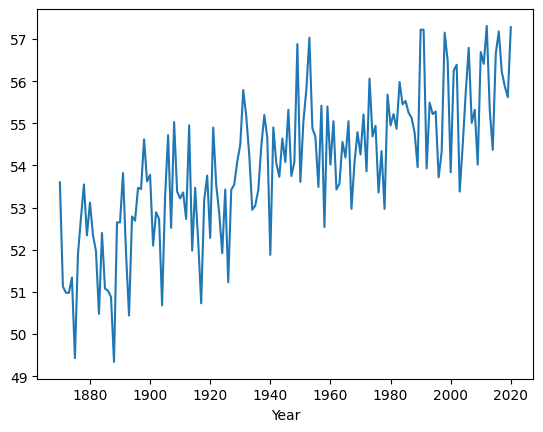

In [32]:
df["Average"].plot()

In [33]:
# Realización de prueba de estacionaridad de Dickey-Fuller
#H0: La serie es NO estacionaria
#H1: La serie es SI estacionaria

from statsmodels.tsa.stattools import adfuller
result = adfuller(df["Average"])
print("El valor p de la prueba de Dickey-Fuller es: ", result[1])

El valor p de la prueba de Dickey-Fuller es:  0.841717253896537


In [34]:
result

(np.float64(-0.719185595116731),
 np.float64(0.841717253896537),
 10,
 140,
 {'1%': np.float64(-3.4779446621720114),
  '5%': np.float64(-2.8824156122448983),
  '10%': np.float64(-2.577901887755102)},
 np.float64(444.8915181430483))

## Conclusión:
No hay evidencia estadistica para rechazar H0 y por lo tanto decir que la serie es estacionaria

In [35]:
#Aplicar primeras diferencias
df["temp_change"]=df["Average"].diff()
df

,Average,temp_change
Year,,
1870,53.60,NaN
1871,51.13,-2.47
1872,50.98,-0.15
1873,50.98,0.00
1874,51.34,0.36
...,...,...
2016,57.18,0.53
2017,56.22,-0.96
2018,55.88,-0.34


In [36]:
df=df.dropna()
df

,Average,temp_change
Year,,
1871,51.13,-2.47
1872,50.98,-0.15
1873,50.98,0.00
1874,51.34,0.36
1875,49.43,-1.91
...,...,...
2016,57.18,0.53
2017,56.22,-0.96
2018,55.88,-0.34


In [37]:
#Aplicacion de la prueba Dickey-Fuller sobre las diferencias
result2 = adfuller(df["temp_change"])
print("El valor p de la prueba de Dickey-Fuller es: ", result2[1])

El valor p de la prueba de Dickey-Fuller es:  8.361907414786182e-14


<Axes: xlabel='Year'>

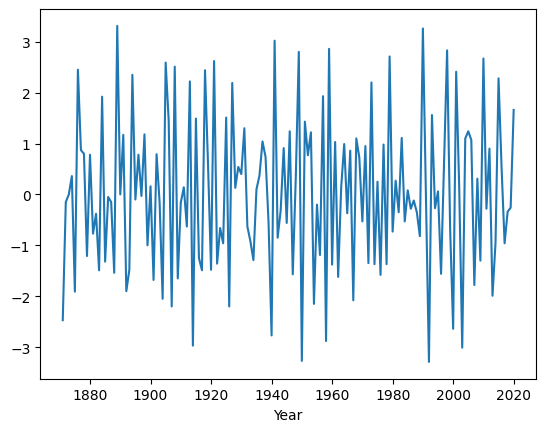

In [38]:
df["temp_change"].plot()

## Conclusion:
La serie transformada de diferencias SI ES ESTACIONARIA

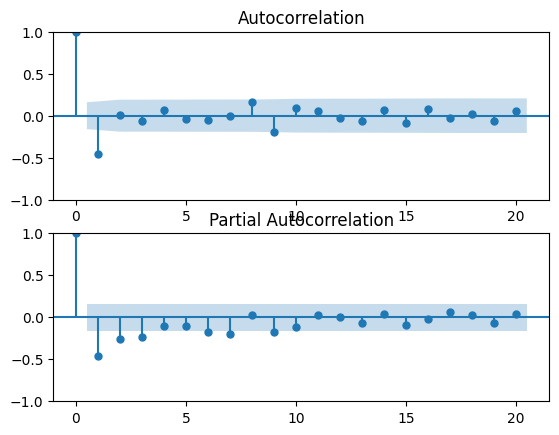

In [39]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, axes = plt.subplots(2,1)

# Graficación de la función de autocorrelación ACF
plot_acf(df["temp_change"], lags=20, ax = axes[0], alpha = 0.05)

# Graficación de la función de autocorrelación parcial PACF
plot_pacf(df["temp_change"], lags=20, ax = axes[1], alpha = 0.05)

plt.show()

In [40]:
# Importación del módulo para estimar un modelo ARIMA
from statsmodels.tsa.arima.model import ARIMA

# Ajustar los datos a un modelo AR(1) e imprimir su AIC:
mod_ar1 = ARIMA(df["temp_change"], order = (1,0,0))
res_ar1 = mod_ar1.fit()
print("El AIC para AR(1) es: ", res_ar1.aic)

El AIC para AR(1) es:  519.9693852277926


In [41]:
# Importación del módulo para estimar un modelo AR(2) e imprimir su AIC
from statsmodels.tsa.arima.model import ARIMA

mod_ar2 = ARIMA(df["temp_change"], order = (2,0,0))
res_ar2 = mod_ar2.fit()
print("El AIC para AR(2) es: ", res_ar2.aic)

El AIC para AR(2) es:  510.4844704559072


In [43]:
# Importación del módulo para estimar un modelo ARIMA(1,0,1)
from statsmodels.tsa.arima.model import ARIMA

# Definir el modelo ARIMA(1,0,1)
mod_ar11 = ARIMA(df["temp_change"], order=(1, 0, 1))
res_ar11 = mod_ar11.fit()
print("El AIC para ARIMA(1,0,1) es:", res_ar11.aic)

El AIC para ARIMA(1,0,1) es: 473.82974970867224


### Conclusión: La serie de tiempo original de temperatura se modela bien con ARIMA(1,1,1)

In [44]:
df = pd.read_csv("TempNY.csv")
df = df.drop("Unnamed: 2", axis = 1)
df.index = df["Year"]
df = df.drop("Year", axis = 1)
df

,Average
Year,
1870,53.60
1871,51.13
1872,50.98
1873,50.98
1874,51.34
...,...
2016,57.18
2017,56.22
2018,55.88


In [45]:
# Importación del módulo ARIMA de statsmodels
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_predict

# Pronóstico de temperaturas usando un modelo ARIMA(1,1,1)
mod = ARIMA(df['Average'], order=(1,1,1))
res = mod.fit()

print(res.summary())

                               SARIMAX Results                                
Dep. Variable:                Average   No. Observations:                  151
Model:                 ARIMA(1, 1, 1)   Log Likelihood                -238.826
Date:                Tue, 20 Oct 2026   AIC                            483.652
Time:                        11:51:35   BIC                            492.683
Sample:                             0   HQIC                           487.321
                                - 151                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0646      0.109      0.590      0.555      -0.150       0.279
ma.L1         -0.8669      0.057    -15.261      0.000      -0.978      -0.756
sigma2         1.4020      0.199      7.043      0.0

In [46]:
predicciones = res.forecast(5)
predicciones

151    56.150446
152    56.077504
153    56.072794
154    56.072490
155    56.072470
Name: predicted_mean, dtype: float64

In [47]:
conf = res.get_forecast(5).conf_int(alpha=0.05)
conf

,lower Average,upper Average
151,53.829710,58.471183
152,53.711871,58.443138
153,53.683072,58.462516
154,53.659996,58.484984
155,53.637485,58.507456
